In [8]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from src.ModelA_init import build_model

In [9]:
tf.keras.utils.set_random_seed(42)

model_a = build_model(verbose=False)

model_a.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model_a.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history_adam_001 = model_a.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=5,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 48s 39ms/step - accuracy: 0.7761 - loss: 0.6166 - val_accuracy: 0.8762 - val_loss: 0.3550
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.9011 - loss: 0.2910 - val_accuracy: 0.9240 - val_loss: 0.2241
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9279 - loss: 0.2175 - val_accuracy: 0.9371 - val_loss: 0.1885
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9391 - loss: 0.1844 - val_accuracy: 0.9414 - val_loss: 0.1750
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9466 - loss: 0.1622 - val_accuracy: 0.9430 - val_loss: 0.1744


In [11]:
val_probabilities = model_a.predict(X_val, batch_size=256)

val_predictions = np.argmax(val_probabilities, axis=1)
val_true = np.asarray(y_val).reshape(-1)

accuracy = accuracy_score(val_true, val_predictions)
macro_f1 = f1_score(val_true, val_predictions, average="macro")

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_predictions,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step
Validation Accuracy: 0.9430
Validation Macro-F1: 0.9010

Classification Report:
              precision    recall  f1-score   support

         CNV       0.96      0.96      0.96      5618
         DME       0.98      0.84      0.90      1740
      Drusen       0.81      0.74      0.78      1330
      Normal       0.95      0.99      0.97      7708

    accuracy                           0.94     16396
   macro avg       0.92      0.88      0.90     16396
weighted avg       0.94      0.94      0.94     16396



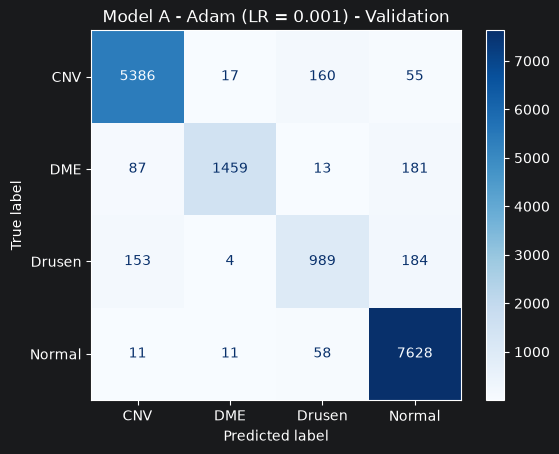

In [12]:
cm = confusion_matrix(
    val_true,
    val_predictions,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CNV", "DME", "Drusen", "Normal"]
)

disp.plot(cmap="Blues")
plt.title("Model A - Adam (LR = 0.001) - Validation")
plt.show()

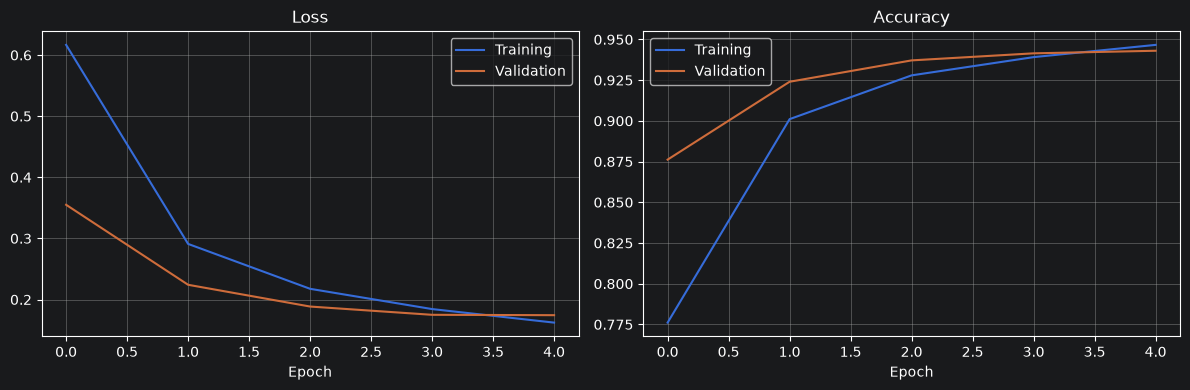

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_adam_001.history["loss"], label="Training")
axes[0].plot(history_adam_001.history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_adam_001.history["accuracy"], label="Training")
axes[1].plot(history_adam_001.history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [14]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_a_0003 = build_model(verbose=False)

model_a_0003.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment 2: Adam, Learning Rate = 0.0003")
print("Trainable Parameters:", model_a_0003.count_params())


Experiment 2: Adam, Learning Rate = 0.0003
Trainable Parameters: 396196


In [15]:
history_adam_0003 = model_a_0003.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=5,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 34ms/step - accuracy: 0.7125 - loss: 0.7799 - val_accuracy: 0.8089 - val_loss: 0.5430
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 43s 36ms/step - accuracy: 0.8282 - loss: 0.4920 - val_accuracy: 0.8562 - val_loss: 0.4151
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 44s 37ms/step - accuracy: 0.8630 - loss: 0.3972 - val_accuracy: 0.8775 - val_loss: 0.3510
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.8882 - loss: 0.3267 - val_accuracy: 0.8937 - val_loss: 0.3081
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 40s 34ms/step - accuracy: 0.9069 - loss: 0.2764 - val_accuracy: 0.9102 - val_loss: 0.2636


In [16]:
val_probabilities_0003 = model_a_0003.predict(
    X_val,
    batch_size=256
)

val_predictions_0003 = np.argmax(
    val_probabilities_0003,
    axis=1
)

val_true = np.asarray(y_val).reshape(-1)

accuracy_0003 = accuracy_score(
    val_true,
    val_predictions_0003
)

macro_f1_0003 = f1_score(
    val_true,
    val_predictions_0003,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy_0003:.4f}")
print(f"Validation Macro-F1: {macro_f1_0003:.4f}")

print(classification_report(
    val_true,
    val_predictions_0003,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step
Validation Accuracy: 0.9102
Validation Macro-F1: 0.8334
              precision    recall  f1-score   support

         CNV       0.93      0.94      0.94      5618
         DME       0.94      0.74      0.83      1740
      Drusen       0.78      0.51      0.62      1330
      Normal       0.90      0.99      0.94      7708

    accuracy                           0.91     16396
   macro avg       0.89      0.80      0.83     16396
weighted avg       0.91      0.91      0.90     16396



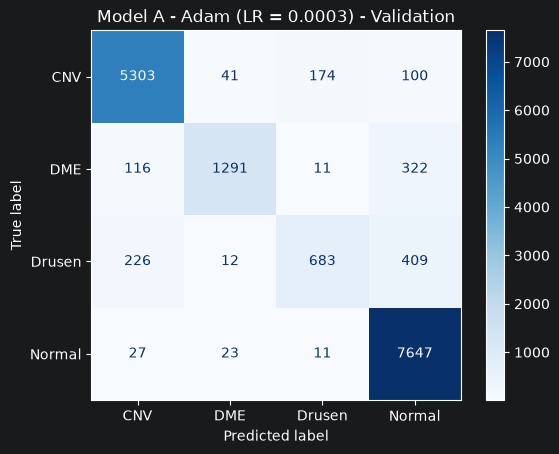

In [17]:
cm = confusion_matrix(
    val_true,
    val_predictions_0003,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CNV", "DME", "Drusen", "Normal"]
)

disp.plot(cmap="Blues")
plt.title("Model A - Adam (LR = 0.0003) - Validation")
plt.show()

In [18]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_a_0005 = build_model(verbose=False)

model_a_0005.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment 3: Adam, Learning Rate = 0.0005")
print("Trainable Parameters:", model_a_0005.count_params())

Experiment 3: Adam, Learning Rate = 0.0005
Trainable Parameters: 396196


In [19]:
history_adam_0005 = model_a_0005.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=5,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 45s 37ms/step - accuracy: 0.7504 - loss: 0.6859 - val_accuracy: 0.8506 - val_loss: 0.4232
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.8702 - loss: 0.3800 - val_accuracy: 0.8920 - val_loss: 0.3091
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9036 - loss: 0.2829 - val_accuracy: 0.9125 - val_loss: 0.2626
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9232 - loss: 0.2292 - val_accuracy: 0.9302 - val_loss: 0.2201
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.9345 - loss: 0.1987 - val_accuracy: 0.9361 - val_loss: 0.1951


In [20]:
val_probabilities_0005 = model_a_0005.predict(
    X_val,
    batch_size=256
)

val_predictions_0005 = np.argmax(
    val_probabilities_0005,
    axis=1
)

val_true = np.asarray(y_val).reshape(-1)

accuracy_0005 = accuracy_score(
    val_true,
    val_predictions_0005
)

macro_f1_0005 = f1_score(
    val_true,
    val_predictions_0005,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy_0005:.4f}")
print(f"Validation Macro-F1: {macro_f1_0005:.4f}")

print(classification_report(
    val_true,
    val_predictions_0005,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step
Validation Accuracy: 0.9361
Validation Macro-F1: 0.8875
              precision    recall  f1-score   support

         CNV       0.94      0.97      0.95      5618
         DME       0.96      0.86      0.91      1740
      Drusen       0.77      0.69      0.73      1330
      Normal       0.96      0.97      0.96      7708

    accuracy                           0.94     16396
   macro avg       0.91      0.87      0.89     16396
weighted avg       0.93      0.94      0.93     16396



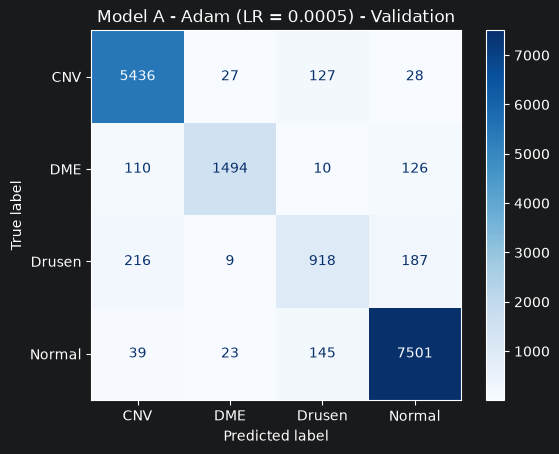

In [21]:
cm = confusion_matrix(
    val_true,
    val_predictions_0005,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CNV", "DME", "Drusen", "Normal"]
)

disp.plot(cmap="Blues")
plt.title("Model A - Adam (LR = 0.0005) - Validation")
plt.show()

In [25]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_a_0001 = build_model(verbose=False)

model_a_0001.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model_a_0001.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history_adam_0001 = model_a_0001.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 46s 37ms/step - accuracy: 0.6650 - loss: 0.8988 - val_accuracy: 0.7390 - val_loss: 0.7441
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.7500 - loss: 0.7023 - val_accuracy: 0.7688 - val_loss: 0.6657
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.7825 - loss: 0.6097 - val_accuracy: 0.7970 - val_loss: 0.5654
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.8118 - loss: 0.5331 - val_accuracy: 0.8261 - val_loss: 0.5065
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.8264 - loss: 0.4916 - val_accuracy: 0.8376 - val_loss: 0.4728


65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step
Validation Accuracy: 0.8376
Validation Macro-F1: 0.6730

Classification Report:
              precision    recall  f1-score   support

         CNV       0.84      0.95      0.89      5618
         DME       0.81      0.55      0.66      1740
      Drusen       0.46      0.17      0.25      1330
      Normal       0.86      0.94      0.90      7708

    accuracy                           0.84     16396
   macro avg       0.74      0.65      0.67     16396
weighted avg       0.82      0.84      0.82     16396



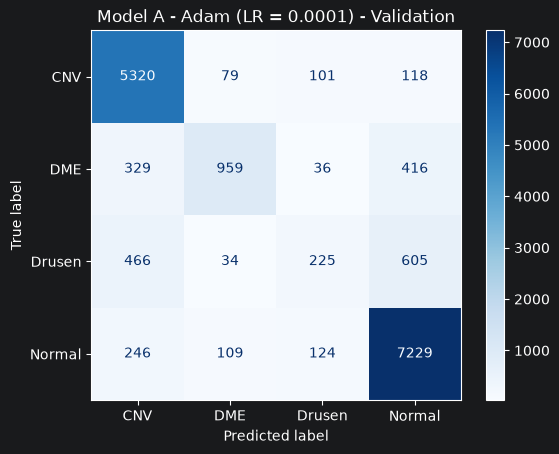

In [27]:
val_probabilities_0001 = model_a_0001.predict(
    X_val,
    batch_size=256
)

val_predictions_0001 = np.argmax(
    val_probabilities_0001,
    axis=1
)

val_true = np.asarray(y_val).reshape(-1)

accuracy_0001 = accuracy_score(
    val_true,
    val_predictions_0001
)

macro_f1_0001 = f1_score(
    val_true,
    val_predictions_0001,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy_0001:.4f}")
print(f"Validation Macro-F1: {macro_f1_0001:.4f}")

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_predictions_0001,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

cm = confusion_matrix(
    val_true,
    val_predictions_0001,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CNV", "DME", "Drusen", "Normal"]
)

disp.plot(cmap="Blues")
plt.title("Model A - Adam (LR = 0.0001) - Validation")
plt.show()

In [28]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_a_0015 = build_model(verbose=False)

model_a_0015.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0015),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model_a_0015.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history_adam_0015 = model_a_0015.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 44s 36ms/step - accuracy: 0.7816 - loss: 0.5953 - val_accuracy: 0.8897 - val_loss: 0.3230
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - accuracy: 0.9111 - loss: 0.2642 - val_accuracy: 0.9260 - val_loss: 0.2198
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9322 - loss: 0.2044 - val_accuracy: 0.9377 - val_loss: 0.1887
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9420 - loss: 0.1750 - val_accuracy: 0.9357 - val_loss: 0.1924
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.9493 - loss: 0.1547 - val_accuracy: 0.9429 - val_loss: 0.1752


65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step
Validation Accuracy: 0.9429
Validation Macro-F1: 0.9035

Classification Report:
              precision    recall  f1-score   support

         CNV       0.96      0.96      0.96      5618
         DME       0.97      0.89      0.93      1740
      Drusen       0.71      0.81      0.75      1330
      Normal       0.97      0.96      0.97      7708

    accuracy                           0.94     16396
   macro avg       0.90      0.91      0.90     16396
weighted avg       0.95      0.94      0.94     16396



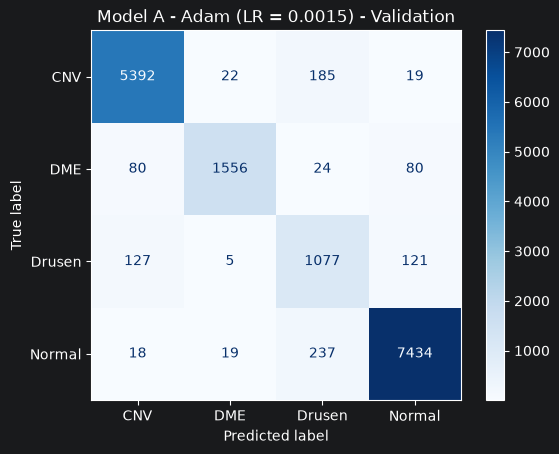

In [31]:
val_probabilities_0015 = model_a_0015.predict(
    X_val,
    batch_size=256
)

val_predictions_0015 = np.argmax(
    val_probabilities_0015,
    axis=1
)

val_true = np.asarray(y_val).reshape(-1)

accuracy_0015 = accuracy_score(
    val_true,
    val_predictions_0015
)

macro_f1_0015 = f1_score(
    val_true,
    val_predictions_0015,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy_0015:.4f}")
print(f"Validation Macro-F1: {macro_f1_0015:.4f}")

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_predictions_0015,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

cm = confusion_matrix(
    val_true,
    val_predictions_0015,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CNV", "DME", "Drusen", "Normal"]
)

disp.plot(cmap="Blues")
plt.title("Model A - Adam (LR = 0.0015) - Validation")
plt.show()

In [38]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
model_a_sgd = build_model(verbose=False)

model_a_sgd.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

history_sgd = model_a_sgd.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 47s 39ms/step - accuracy: 0.4704 - loss: 1.1707 - val_accuracy: 0.4703 - val_loss: 1.1611
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.4913 - loss: 1.1471 - val_accuracy: 0.4870 - val_loss: 1.1412
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 41s 34ms/step - accuracy: 0.5700 - loss: 1.0790 - val_accuracy: 0.6703 - val_loss: 0.9588
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 69s 57ms/step - accuracy: 0.6772 - loss: 0.9095 - val_accuracy: 0.7224 - val_loss: 0.8130
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 48s 40ms/step - accuracy: 0.7141 - loss: 0.8127 - val_accuracy: 0.7357 - val_loss: 0.7574


In [39]:
val_probabilities_sgd = model_a_sgd.predict(
    X_val, batch_size=256
)

val_predictions_sgd = np.argmax(
    val_probabilities_sgd, axis=1
)

print("SGD Validation Accuracy:",
      accuracy_score(val_true, val_predictions_sgd))

print("SGD Validation Macro-F1:",
      f1_score(val_true, val_predictions_sgd,
               average="macro", zero_division=0))

print(classification_report(
    val_true,
    val_predictions_sgd,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
SGD Validation Accuracy: 0.7357282263966821
SGD Validation Macro-F1: 0.4066436114700922
              precision    recall  f1-score   support

         CNV       0.72      0.90      0.80      5618
         DME       0.50      0.00      0.01      1740
      Drusen       0.00      0.00      0.00      1330
      Normal       0.75      0.91      0.82      7708

    accuracy                           0.74     16396
   macro avg       0.49      0.45      0.41     16396
weighted avg       0.65      0.74      0.66     16396



In [34]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_a_sgd_momentum = build_model(verbose=False)

model_a_sgd_momentum.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

model_a_sgd_momentum.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution1 (Conv2D)           │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling1 (MaxPooling2D)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution2 (Conv2D)           │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling2 (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution3 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling3 (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Convolution4 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MaxPooling4 (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ GlobalAveragePooling            │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DenseHidden (Dense)             │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,196 (1.51 MB)

 Trainable params: 396,196 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history_sgd_momentum = model_a_sgd_momentum.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    shuffle=True,
    verbose=1
)

Epoch 1/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 43s 35ms/step - accuracy: 0.6122 - loss: 0.9698 - val_accuracy: 0.7512 - val_loss: 0.6919
Epoch 2/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 43s 36ms/step - accuracy: 0.7958 - loss: 0.5805 - val_accuracy: 0.8486 - val_loss: 0.4393
Epoch 3/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.8576 - loss: 0.4157 - val_accuracy: 0.8824 - val_loss: 0.3395
Epoch 4/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 42s 35ms/step - accuracy: 0.8900 - loss: 0.3210 - val_accuracy: 0.9045 - val_loss: 0.2862
Epoch 5/5
1196/1196 ━━━━━━━━━━━━━━━━━━━━ 47s 40ms/step - accuracy: 0.9121 - loss: 0.2609 - val_accuracy: 0.9182 - val_loss: 0.2463


In [36]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

val_true = np.asarray(y_val).reshape(-1)

val_probabilities_momentum = model_a_sgd_momentum.predict(
    X_val,
    batch_size=256
)

val_predictions_momentum = np.argmax(
    val_probabilities_momentum,
    axis=1
)

accuracy_momentum = accuracy_score(
    val_true,
    val_predictions_momentum
)

macro_f1_momentum = f1_score(
    val_true,
    val_predictions_momentum,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy_momentum:.4f}")
print(f"Validation Macro-F1: {macro_f1_momentum:.4f}")

print("\nClassification Report:")
print(classification_report(
    val_true,
    val_predictions_momentum,
    labels=[0, 1, 2, 3],
    target_names=["CNV", "DME", "Drusen", "Normal"],
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step
Validation Accuracy: 0.9182
Validation Macro-F1: 0.8555

Classification Report:
              precision    recall  f1-score   support

         CNV       0.96      0.93      0.94      5618
         DME       0.93      0.79      0.85      1740
      Drusen       0.71      0.64      0.67      1330
      Normal       0.92      0.99      0.95      7708

    accuracy                           0.92     16396
   macro avg       0.88      0.84      0.86     16396
weighted avg       0.92      0.92      0.92     16396



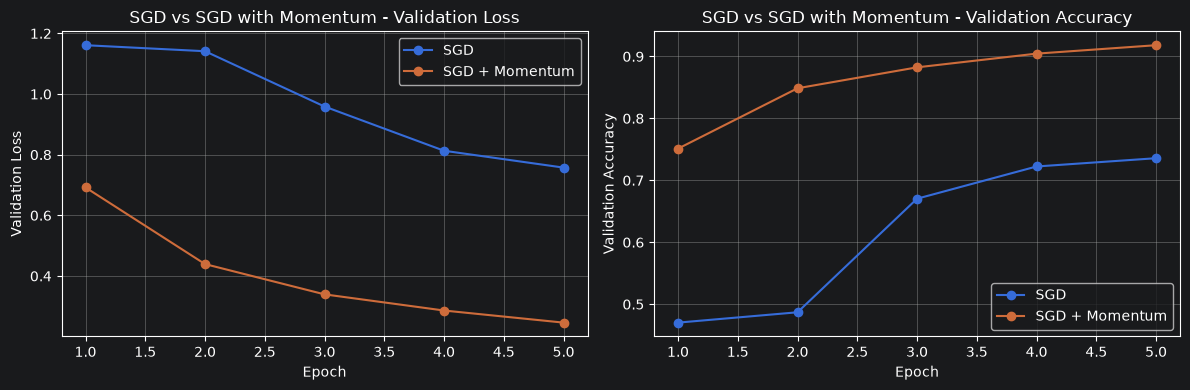

In [40]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

histories = {
    "SGD": history_sgd,
    "SGD + Momentum": history_sgd_momentum
}

for name, history in histories.items():

    epochs = range(1, len(history.history["val_loss"]) + 1)

    axes[0].plot(
        epochs,
        history.history["val_loss"],
        marker="o",
        label=name
    )

    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        marker="o",
        label=name
    )

axes[0].set_title("SGD vs SGD with Momentum - Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("SGD vs SGD with Momentum - Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()